# Step 1: Import the necessary libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Step 2: Create the dataset

In [5]:
# Set the random seed for reproducibility
np.random.seed()
# Create a synthetic dataset
data = {
    'product_id': range(1, 21),  # Example product IDs from 1 to 20
    'product_name': [f'Product {i}' for i in range(1, 21)],  # Example product names from Product 1 to Product 20
    'category': np.random.choice(['Electronics', 'Clothing', 'Home', 'Books'], size=20),  # Randomly assign categories to products
    'units_sold': np.random.poisson(lam=50, size=20),  # Randomly assign units sold using a Poisson distribution
    'sale_data': pd.date_range(start='2023-01-01', periods=20, freq='D')  # Example sale dates for each product
}

sales_data = pd.DataFrame(data)
print("-" * 10 + "Sales Data" + "-" * 10)
print(sales_data)


----------Sales Data----------
    product_id product_name     category  units_sold  sale_data
0            1    Product 1  Electronics          32 2023-01-01
1            2    Product 2         Home          62 2023-01-02
2            3    Product 3     Clothing          51 2023-01-03
3            4    Product 4     Clothing          53 2023-01-04
4            5    Product 5         Home          51 2023-01-05
5            6    Product 6     Clothing          54 2023-01-06
6            7    Product 7         Home          57 2023-01-07
7            8    Product 8         Home          48 2023-01-08
8            9    Product 9  Electronics          50 2023-01-09
9           10   Product 10  Electronics          58 2023-01-10
10          11   Product 11     Clothing          47 2023-01-11
11          12   Product 12        Books          51 2023-01-12
12          13   Product 13  Electronics          67 2023-01-13
13          14   Product 14     Clothing          63 2023-01-14
14       

In [7]:
# Save the DataFrame as a CSV file
sales_data.to_csv('sales_data.csv', index=False)
print("Sales data saved to 'sales_data.csv'")

Sales data saved to 'sales_data.csv'


In [8]:
import os
os.getcwd()

'c:\\My-Drive\\Learning\\repositories\\ai-learning\\AI-Naresh-IT\\statistics'

# Step 3: Descriptive statistics

In [19]:
# Descriptive statistics
descriptive_stats = sales_data['units_sold'].describe()
# Display descriptive statistics
print("\nDescriptive Statistics for 'units_sold'")
print(descriptive_stats)

# Additional descriptive statistics
mean_sales = sales_data['units_sold'].mean()
median_sales = sales_data['units_sold'].median()
mode_sales = sales_data['units_sold'].mode()[0]
variance_sales = sales_data['units_sold'].var()
std_deviation_sales = sales_data['units_sold'].std()
# Group by category and calculate total and average sales
category_stats = sales_data.groupby('category')['units_sold'].agg(['sum', 'mean', 'std']).reset_index()
category_stats.columns = ['Category','Total units Sold', 'Average units Sold', 'std Dev of units Sold']

#Display the results
print("\nStatistical Analysis:")
print("-" * 30)
print(f"Mean Units Sold: {mean_sales}")
print(f"Median Units Sold: {median_sales}")
print(f"Mode Units Sold: {mode_sales}")
print(f"Variance Units Sold: {variance_sales}")
print(f"Standard Deviation Units Sold: {std_deviation_sales}")
print("\nTotal, Average, and Std Dev of Sales by Category:")
print("-" * 30)
print(category_stats)



Descriptive Statistics for 'units_sold'
count    20.000000
mean     51.650000
std       7.555235
min      32.000000
25%      48.750000
50%      50.500000
75%      54.750000
max      67.000000
Name: units_sold, dtype: float64

Statistical Analysis:
------------------------------
Mean Units Sold: 51.65
Median Units Sold: 50.5
Mode Units Sold: 50
Variance Units Sold: 57.08157894736843
Standard Deviation Units Sold: 7.5552352013268536

Total, Average, and Std Dev of Sales by Category:
------------------------------
      Category  Total units Sold  Average units Sold  std Dev of units Sold
0        Books               101           50.500000               0.707107
1     Clothing               361           51.571429               6.267832
2  Electronics               207           51.750000              14.885675
3         Home               364           52.000000               5.477226


# Step 4 Inferential Statistics

In [12]:
# Confidence Interval for the mean of 'units_sold'
confidence_level = 0.95
degrees_of_freedom = len(sales_data['units_sold']) - 1
sample_mean = mean_sales
sample_standard_error = std_deviation_sales / np.sqrt(len(sales_data['units_sold']))

# t-score for the confidence level
t_score = stats.t.ppf((1 + confidence_level) / 2, degrees_of_freedom)
margin_of_error = t_score * sample_standard_error

confidence_interval = (sample_mean - margin_of_error, sample_mean + margin_of_error)
print("\nConfidence Interval for the mean of 'units_sold'")
print(confidence_interval)


Confidence Interval for the mean of 'units_sold'
(np.float64(48.11404108188813), np.float64(55.185958918111865))


# Hypothesis Testing

In [13]:
# Hypothesis Testing (t-test)
# Null hypothesis: Mean units sold is equal to 20
# Alternative hypothesis: Mean units sold is not equal to 20

t_statistic, p_value = stats.ttest_1samp(sales_data['units_sold'], 20)

print("\nHypothesis Testing (t-test)")
print(f"t-statistic: {t_statistic}")
print(f"p-value: {p_value}")

# Conclusion
if p_value < 0.05:
    print("Reject the null hypothesis: Mean units sold is significantly different from 20")
else:
    print("Fail to reject the null hypothesis: Mean units sold is not significantly different from 20")



Hypothesis Testing (t-test)
t-statistic: 18.734440319062312
p-value: 1.0415029027122554e-13
Reject the null hypothesis: Mean units sold is significantly different from 20


# Visualization of Sales Data

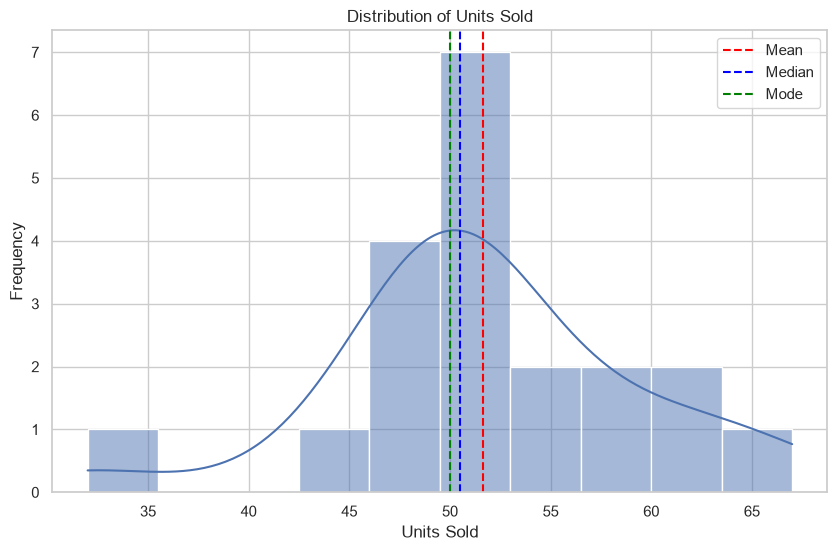

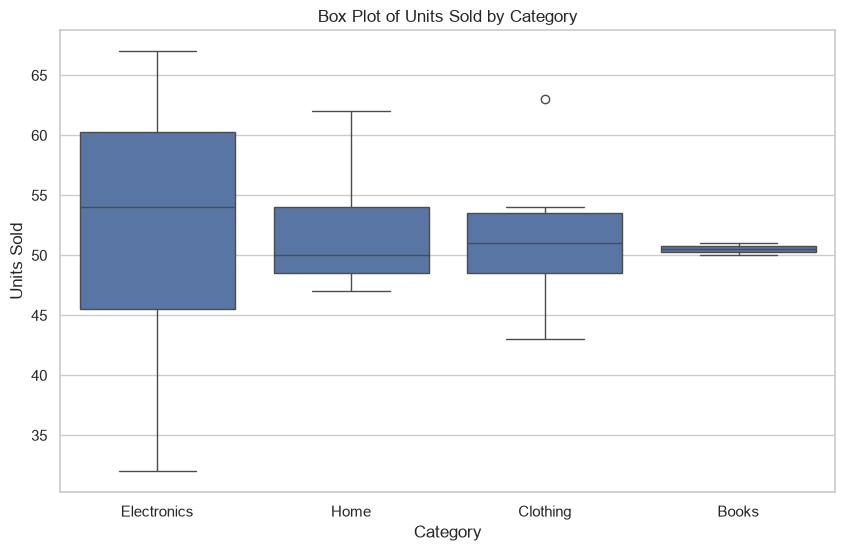

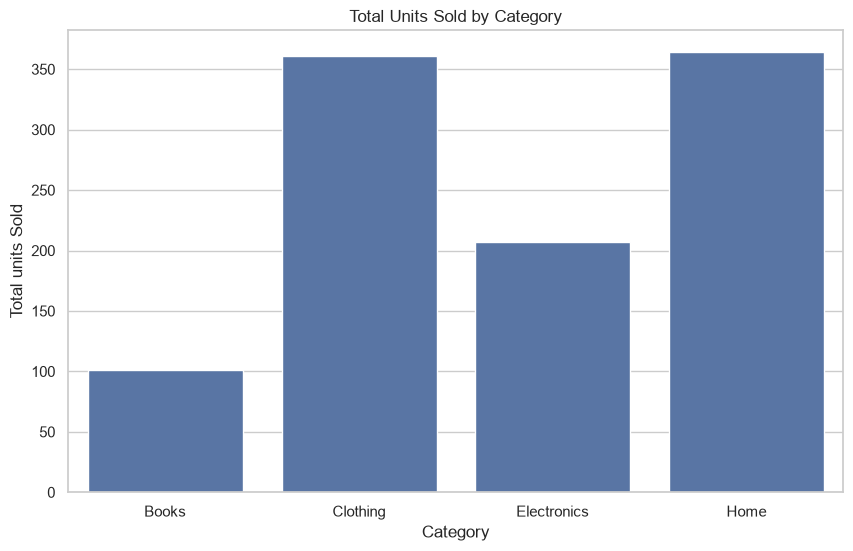

In [21]:
# Visualization
sns.set(style="whitegrid")
# plot the distribution of units sold
plt.figure(figsize=(10, 6))
sns.histplot(sales_data['units_sold'],bins=10, kde=True)
plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")
plt.axvline(mean_sales, color='red', linestyle='--', label='Mean')
plt.axvline(median_sales, color='blue', linestyle='--', label='Median')
plt.axvline(mode_sales, color='green', linestyle='--', label='Mode')
plt.legend()
plt.show()

# Box for units sold by category
plt.figure(figsize=(10, 6))
sns.boxplot(x='category', y='units_sold', data=sales_data)
plt.title("Box Plot of Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.show()

# Bar plot of total units sold by category
plt.figure(figsize=(10, 6))
sns.barplot(x='Category', y='Total units Sold', data=category_stats)
plt.title("Total Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Total units Sold")
plt.show()